# Pauli-Y results
Two figures: entropy versus size, and entropy density versus probability, each with a detailed high-probability panel. Shading is one SEM using the actual realisation count. No simulations run here.

Place `pauli_plotting.py` in `src/monitored_cluster_states/` and this notebook in `notebooks/`. Select a file explicitly if the directory contains several datasets.


In [1]:
from monitored_cluster_states.paths import DATA_DIR, FIGURES_DIR
import monitored_cluster_states.pauli_plotting as plotting
import importlib
import numpy as np
import matplotlib.pyplot as plt

plotting = importlib.reload(plotting)


In [2]:
BASIS = "y"
FILE_NAME = None  # Set to the exact .pkl filename if several files exist.
MAX_P_CURVES = 10  # Set to None to show all stored probabilities on the left.
SHOW_SEM = True
SAVE_PDF = True
output_dir = FIGURES_DIR / f"pauli_{BASIS}" if SAVE_PDF else None

results = plotting.load_pauli_results(
    DATA_DIR / f"pauli_{BASIS}", FILE_NAME, basis=BASIS,
)
print("Loaded:", results["data_file"])
print("Protocol:", results["metadata"].get("measurement_protocol", "not recorded"))
print("Periodic:", results["metadata"].get("periodic", "not recorded"))
counts = results["counts"][results["counts"] > 0]
print("Realisations per point:", counts.min(), "to", counts.max())

# Select actual stored probabilities and all available sizes.
p_values = results["probabilities"]
n_curves = len(p_values) if MAX_P_CURVES is None else min(MAX_P_CURVES, len(p_values))
p_indices = np.unique(np.linspace(0, len(p_values) - 1, n_curves, dtype=int))
P_TARGETS = p_values[p_indices]
L_TARGETS = results["sizes"]


Loaded: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations-main\data_files\pauli_y\pauli_y_results_PBC_binary_rank_all.pkl
Protocol: Y_current_graph_LC_delete_with_local_corrections
Periodic: True
Realisations per point: 50 to 50


## Entropy density versus probability
Left: full range. Right: zoom from 0.85 to 1, matching the supplied notebook. Mean and SEM are both divided by L.

Selected sizes: [40 50 60 70 80]
Saved: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations-main\results\figures\pauli_y\pauli_y_results_PBC_binary_rank_all_S_over_L_vs_p_two_panels.pdf


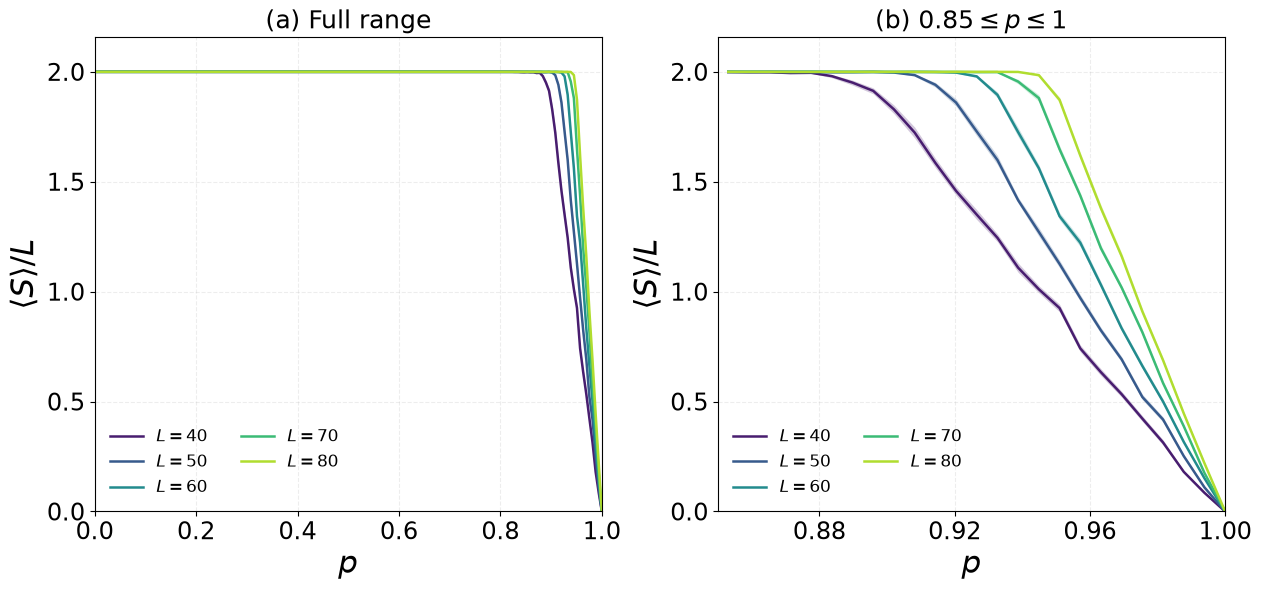

In [3]:
density_plot = plotting.plot_pauli_density_vs_p(
    results, output_dir, L_targets=L_TARGETS,
    zoom=(0.85, 1.0), show_sem=SHOW_SEM,
)
plt.show()


## Entropy versus size
Left: probabilities nearest the selected targets. Right: all stored probabilities in the zoom interval.

Saved: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations-main\results\figures\pauli_y\pauli_y_results_PBC_binary_rank_all_S_vs_L_two_panels.pdf
Actual selected probabilities: [0.         0.14285714 0.3        0.45714286 0.61428571 0.73061224
 0.79795918 0.86530612 0.93265306 1.        ]


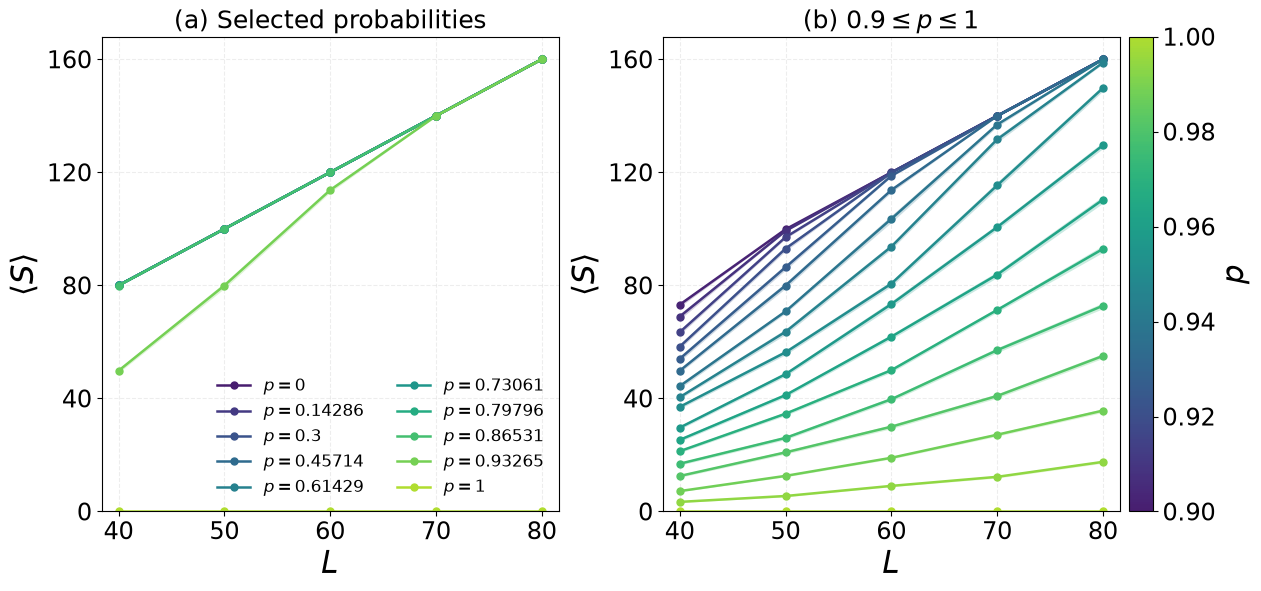

In [3]:
size_plot = plotting.plot_pauli_entropy_vs_L(
    results, output_dir, p_targets=P_TARGETS,
    zoom=(0.9, 1.0), show_sem=SHOW_SEM,
)
print("Actual selected probabilities:", size_plot["selected_probabilities"])
plt.show()


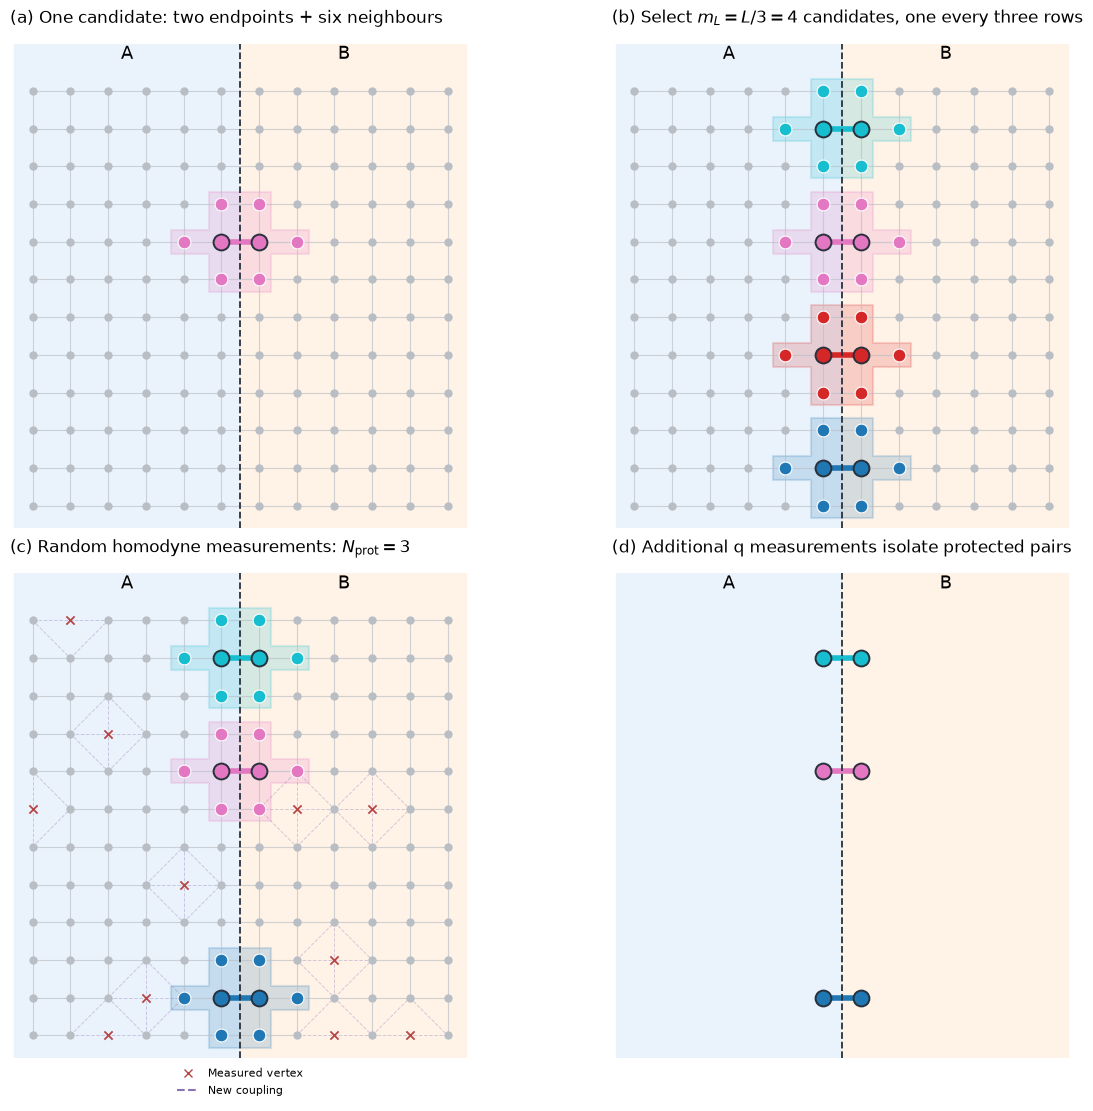

In [10]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon  


def plot_protected_pairs(
    L=12,
    p=0.08,
    r=1.0,
    w=1.0,
    phi=np.pi / 4,
    seed=7,
):
    if L < 6 or L % 2:
        raise ValueError("Choose an even L >= 6.")
    if np.isclose(np.sin(phi), 0):
        raise ValueError("Choose a non-position angle.")

    rng = np.random.default_rng(seed)

    # Original square lattice and vertical bipartition.
    G = nx.grid_2d_graph(L, L)
    nodes = list(G.nodes)
    index = {v: k for k, v in enumerate(nodes)}
    pos = {v: v for v in nodes}

    left = L // 2 - 1
    cut_x = left + 0.5

    # Each candidate has a complete bulk neighbourhood.
    # Their neighbourhoods occupy disjoint groups of three rows.
    rows = list(range(1, L - 1, 3))
    candidates = [((left, y), (left + 1, y)) for y in rows]

    def neighbourhood(edge):
        i, j = edge
        return {i, j} | set(G.neighbors(i)) | set(G.neighbors(j))

    patches = [neighbourhood(e) for e in candidates]
    m_L = len(candidates)

    # Random measurement pattern: each vertex is measured with probability p.
    measured = {v for v in nodes if rng.random() < p}
    survivors = [v for v in nodes if v not in measured]

    protected = [
        k for k, patch in enumerate(patches)
        if patch.isdisjoint(measured)
    ]
    protected_edges = [candidates[k] for k in protected]
    endpoints = {v for e in protected_edges for v in e}
    N_prot = len(protected)

    # Exact conditional Gaussian graph, before any plotting threshold.
    A = nx.to_numpy_array(G, nodelist=nodes)
    Z = w * A + 1j * np.exp(-2 * r) * np.eye(len(nodes))

    R = [index[v] for v in survivors]
    M = [index[v] for v in nodes if v in measured]

    Z_eff = Z[np.ix_(R, R)].copy()

    if M:
        B = Z[np.ix_(M, M)] + (
            np.cos(phi) / np.sin(phi)
        ) * np.eye(len(M))

        Z_eff -= Z[np.ix_(R, M)] @ np.linalg.solve(
            B, Z[np.ix_(M, R)]
        )

    # Only appreciable new couplings are drawn to keep panel 3 readable.
    # This threshold is for visualization, not a connectivity test.
    draw_threshold = 0.03 * w
    rewired_edges = []

    for a, u in enumerate(survivors):
        for b in range(a + 1, len(survivors)):
            v = survivors[b]
            if not G.has_edge(u, v) and abs(Z_eff[a, b]) > draw_threshold:
                rewired_edges.append((u, v))

    colors = plt.cm.tab10(np.linspace(0, 1, max(m_L, 2)))
    grey = "#b9bec5"
    dark = "#28313b"

    fig, axes = plt.subplots(
        2, 2, figsize=(12, 11), constrained_layout=True
    )

    def prepare(ax, title):
        ax.axvspan(-0.5, cut_x, color="#eaf2fb", zorder=0)
        ax.axvspan(cut_x, L - 0.5, color="#fff2e7", zorder=0)
        ax.axvline(cut_x, color=dark, ls="--", lw=1.3)

        ax.text(left / 2, L - 0.15, "A", ha="center", fontsize=13)
        ax.text(
            (cut_x + L - 1) / 2, L - 0.15,
            "B", ha="center", fontsize=13
        )

        ax.set_title(title, loc="left", fontsize=12, pad=15)
        ax.set_xlim(-0.6, L - 0.4)
        ax.set_ylim(-0.6, L + 0.25)
        ax.set_aspect("equal")
        ax.set_axis_off()

    def draw_base(ax, visible_nodes, visible_edges):
        nx.draw_networkx_edges(
            G, pos, ax=ax, edgelist=list(visible_edges),
            edge_color=grey, width=0.8, alpha=0.65
        )
        nx.draw_networkx_nodes(
            G, pos, ax=ax, nodelist=list(visible_nodes),
            node_color=grey, node_size=25
        )

    def shade_candidate(ax, k):
        (_, y), _ = candidates[k]
        x = left
        pad = 0.32

        # Outline enclosing the two endpoints and their six neighbours.
        outline = [
            (x - pad,     y + 1 + pad),
            (x + 1 + pad, y + 1 + pad),
            (x + 1 + pad, y + pad),
            (x + 2 + pad, y + pad),
            (x + 2 + pad, y - pad),
            (x + 1 + pad, y - pad),
            (x + 1 + pad, y - 1 - pad),
            (x - pad,     y - 1 - pad),
            (x - pad,     y - pad),
            (x - 1 - pad, y - pad),
            (x - 1 - pad, y + pad),
            (x - pad,     y + pad),
        ]

        ax.add_patch(
            Polygon(
                outline,
                closed=True,
                facecolor=colors[k],
                edgecolor=colors[k],
                alpha=0.18,
                linewidth=1.5,
                joinstyle="round",
                zorder=0.5,
            )
        )

    def highlight(ax, k, show_neighbours=True):
        edge = candidates[k]
        color = colors[k]

        if show_neighbours:
            shade_candidate(ax, k)
            neighbours = list(patches[k] - set(edge))
            nx.draw_networkx_nodes(
                G, pos, ax=ax, nodelist=neighbours,
                node_color=[color], node_size=85,
                edgecolors="white", linewidths=0.8
            )

        nx.draw_networkx_edges(
            G, pos, ax=ax, edgelist=[edge],
            edge_color=[color], width=4
        )
        nx.draw_networkx_nodes(
            G, pos, ax=ax, nodelist=list(edge),
            node_color=[color], node_size=130,
            edgecolors=dark, linewidths=1.4
        )

    # (a) A single eight-vertex neighbourhood.
    ax = axes[0, 0]
    prepare(ax, "(a) One candidate: two endpoints + six neighbours")
    draw_base(ax, nodes, G.edges)
    highlight(ax, len(candidates) // 2)

    # (b) All candidate neighbourhoods.
    ax = axes[0, 1]
    prepare(ax, rf"(b) Select $m_L=L/3={m_L}$ candidates, one every three rows")
    draw_base(ax, nodes, G.edges)

    for k in range(m_L):
        highlight(ax, k)

    # (c) State after the random homodyne measurements.
    ax = axes[1, 0]
    prepare(
        ax,
        rf"(c) Random homodyne measurements: $N_{{\rm prot}}={N_prot}$"
    )

    original_surviving_edges = [
        (u, v) for u, v in G.edges
        if u not in measured and v not in measured
    ]
    draw_base(ax, survivors, original_surviving_edges)

    nx.draw_networkx_edges(
        G, pos, ax=ax, edgelist=rewired_edges,
        edge_color="#8b73b5", style="dashed",
        width=0.7, alpha=0.35
    )

    if measured:
        xy = np.array(list(measured))
        ax.scatter(
            xy[:, 0], xy[:, 1],
            marker="x", color="#b74747", s=35, linewidths=1.3,
            zorder=5
        )

    for k in protected:
        highlight(ax, k)

    ax.legend(
        handles=[
            Line2D(
                [], [], marker="x", ls="", color="#b74747",
                label="Measured vertex"
            ),
            Line2D(
                [], [], ls="--", color="#8b73b5",
                label="New coupling"
            ),
        ],
        loc="lower center", bbox_to_anchor=(0.5, -0.10),
        frameon=False, fontsize=8
    )

    # (d) Auxiliary q measurements delete all other surviving modes.
    ax = axes[1, 1]
    prepare(ax, "(d) Additional q measurements isolate protected pairs")

    for k in protected:
        highlight(ax, k, show_neighbours=False)

    if not protected:
        ax.text(
            cut_x, L / 2, "No protected pairs in this realization",
            ha="center", fontsize=11
        )


    return fig, axes


fig, axes = plot_protected_pairs()
plt.show()

# Optional:
# fig.savefig("protected_pairs.pdf", bbox_inches="tight")